# Análise Exploratória de Dados (AED)

Este notebook foi criado para organizar a análise exploratória dos dados do projeto. Os objetivos são:  (1)Entender estrutura e qualidade dos dados; (2) Identificar padrões iniciais e possíveis outliers; e (3) Preparar insights para etapas posteriores do projeto.

### Introdução

A Aventura é uma produtora e gestora cultural referência no Brasil, com forte atuação na criação de espetáculos e na gestão de teatros, promovendo experiências artísticas de alta qualidade para diferentes públicos. Inserido nesse contexto, o projeto propõe o desenvolvimento de uma solução digital para o Portal Aventura, com foco em ampliar o alcance de seus conteúdos e fortalecer a conexão entre espectadores e o ecossistema cultural da empresa.

### Contextualização do Problema

Atualmente, o Portal Aventura não possui um sistema estruturado de recomendação de conteúdos e espetáculos. Dessa forma, a navegação do usuário ocorre principalmente a partir do acesso a páginas específicas, sem a apresecntação de sugestões relacionadas a outras experiências disponíveis no portal, o que pode reduzir o potencial de conversão e geração de receita.

### Objetivo do Sistema

O objetivo do sistema é desenvolver uma solução de recomendação inteligente capaz de sugerir espetáculos, conteúdos e experiências alinhadas aos interesses dos usuários. Com isso, busca-se aumentar o tempo de permanência no portal, estimular a navegação entre diferentes conteúdos e impulsionar a venda de ingressos, criando uma jornada mais conectada e personalizada dentro do ecossistema da Aventura.

# Importação dos dados e tratamento

In [ ]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from pathlib import Path

sns.set_theme(style="whitegrid")

# Carregamento da base
base_path = Path("docs/database_sympla.csv")
if not base_path.exists():
    base_path = Path("database_sympla.csv")

try:
    df = pd.read_csv(base_path)
except UnicodeDecodeError:
    df = pd.read_csv(base_path, encoding="latin1")

# Cópia para transformações de análise
df_eda = df.copy()

# Tratando vírgula/ponto e possíveis símbolos
df_eda["VALOR_NUM"] = (
    df_eda["VALOR DO INGRESSO"].astype(str)
    .str.replace(r"[^0-9,.-]", "", regex=True)
    .str.replace(".", "", regex=False)
    .str.replace(",", ".", regex=False)
)
df_eda["VALOR_NUM"] = pd.to_numeric(df_eda["VALOR_NUM"], errors="coerce")

# Conversão de datas
df_eda["DATA_APRESENTACAO_DT"] = pd.to_datetime(df_eda["DATA DA APRESENTAÇÃO"], errors="coerce")
df_eda["DATA_COMPRA_DT"] = pd.to_datetime(df_eda["DATA DA COMPRA"], errors="coerce")

# Antecedência de compra em dias (compra -> apresentação), arredondada para inteiro
df_eda["ANTECEDENCIA_DIAS"] = (
    (df_eda["DATA_APRESENTACAO_DT"] - df_eda["DATA_COMPRA_DT"]).dt.total_seconds() / 86400
).round().astype("Int64")

print(f"Linhas: {df_eda.shape[0]} | Colunas: {df_eda.shape[1]}")
df_eda.head()

Matplotlib is building the font cache; this may take a moment.
/var/folders/nv/cxjnj7v93ss6407r7sspcqyr0000gp/T/ipykernel_55996/3886818228.py:32: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  df_eda["DATA_APRESENTACAO_DT"] = pd.to_datetime(df_eda["DATA DA APRESENTAÇÃO"], errors="coerce")
/var/folders/nv/cxjnj7v93ss6407r7sspcqyr0000gp/T/ipykernel_55996/3886818228.py:33: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  df_eda["DATA_COMPRA_DT"] = pd.to_datetime(df_eda["DATA DA COMPRA"], errors="coerce")


Linhas: 343758 | Colunas: 14


,ID COMPRADOR.1.ID USUÁRIO,NOME ESPETÁCULO,TEATRO,DATA DA APRESENTAÇÃO,DATA DA COMPRA,SETOR,VALOR DO INGRESSO,MÉTODO DE PAGAMENTO,CANAL DA VENDA,TIPO,VALOR_NUM,DATA_APRESENTACAO_DT,DATA_COMPRA_DT,ANTECEDENCIA_DIAS
0,1,UM MALLANDRO NA QUARENTENA COM SERGIO MALLANDRO,TEATRO RIACHUELO RJ,6/26/21 20:00,5/20/21 5:03,PLATEIA VIP - 02 PESSOAS,120,BOLETO,WEB,Show Stand-Up,120.0,2021-06-26 20:00:00,2021-05-20 05:03:00,37.622917
1,1,UM MALLANDRO NA QUARENTENA COM SERGIO MALLANDRO,TEATRO RIACHUELO RJ,6/26/21 20:00,5/20/21 5:03,PLATEIA VIP - 02 PESSOAS,120,BOLETO,WEB,Show Stand-Up,120.0,2021-06-26 20:00:00,2021-05-20 05:03:00,37.622917
2,2,DOMINGUINHOS - ISSO AQUI TÁ BOM DEMAIS,TEATRO RIACHUELO RJ,6/9/23 20:00,6/9/23 10:04,BALCÃO,50,CARTAO DE CREDITO,WEB,Show Musical,50.0,2023-06-09 20:00:00,2023-06-09 10:04:00,0.413889
3,2,DOMINGUINHOS - ISSO AQUI TÁ BOM DEMAIS,TEATRO RIACHUELO RJ,6/9/23 20:00,6/9/23 10:04,BALCÃO,50,CARTAO DE CREDITO,WEB,Show Musical,50.0,2023-06-09 20:00:00,2023-06-09 10:04:00,0.413889
4,3,A NOVIÇA REBELDE,TEATRO RIACHUELO RJ,5/11/24 19:00,5/10/24 20:33,PLATEIA,225,CARTAO DE CREDITO,WEB,Espetáculo Musical,225.0,2024-05-11 19:00:00,2024-05-10 20:33:00,0.935417


## 1) Análise básica de entendimento da base

Nesta etapa respondemos:
- Quantas linhas e colunas existem?
- O que cada variável representa?
- Existem dados faltantes?
- Há registros duplicados?

In [7]:
# Visão geral da base
print(f"Dimensão da base: {df_eda.shape[0]:,} linhas x {df.shape[1]} colunas".replace(",", "."))

# Dicionário de dados (descrição funcional de cada variável original)
dicionario = pd.DataFrame(
    {
        "Variável": [
            "ID COMPRADOR.1.ID USUÁRIO",
            "NOME ESPETÁCULO",
            "TEATRO",
            "DATA DA APRESENTAÇÃO",
            "DATA DA COMPRA",
            "SETOR",
            "VALOR DO INGRESSO",
            "MÉTODO DE PAGAMENTO",
            "CANAL DA VENDA",
            "TIPO",
        ],
        "Descrição": [
            "Identificador único do comprador/usuário.",
            "Nome do espetáculo ou evento comprado.",
            "Teatro/local onde ocorre a apresentação.",
            "Data e horário da apresentação.",
            "Data e horário da compra do ingresso.",
            "Setor/localização do assento ou categoria no teatro.",
            "Valor bruto do ingresso (texto na base original).",
            "Forma de pagamento utilizada na compra.",
            "Canal utilizado para realizar a venda (WEB, APP, bilheteria etc.).",
            "Categoria do evento (ex.: musical, teatral, dança, stand-up).",
        ],
    }
)

dicionario

Dimensão da base: 343.758 linhas x 10 colunas


,Variável,Descrição
0,ID COMPRADOR.1.ID USUÁRIO,Identificador único do comprador/usuário.
1,NOME ESPETÁCULO,Nome do espetáculo ou evento comprado.
2,TEATRO,Teatro/local onde ocorre a apresentação.
3,DATA DA APRESENTAÇÃO,Data e horário da apresentação.
4,DATA DA COMPRA,Data e horário da compra do ingresso.
5,SETOR,Setor/localização do assento ou categoria no t...
6,VALOR DO INGRESSO,Valor bruto do ingresso (texto na base original).
7,MÉTODO DE PAGAMENTO,Forma de pagamento utilizada na compra.
8,CANAL DA VENDA,"Canal utilizado para realizar a venda (WEB, AP..."
9,TIPO,"Categoria do evento (ex.: musical, teatral, da..."


In [8]:
# Dados faltantes e duplicados
faltantes = pd.DataFrame(
    {
        "qtd_faltante": df.isna().sum(),
        "perc_faltante": (df.isna().mean() * 100).round(4),
    }
).sort_values("qtd_faltante", ascending=False)

print("Total de linhas duplicadas:", df.duplicated().sum())
faltantes

Total de linhas duplicadas: 172741


,qtd_faltante,perc_faltante
DATA DA APRESENTAÇÃO,1,0.0003
DATA DA COMPRA,1,0.0003
SETOR,1,0.0003
VALOR DO INGRESSO,1,0.0003
MÉTODO DE PAGAMENTO,1,0.0003
CANAL DA VENDA,1,0.0003
TIPO,1,0.0003
ID COMPRADOR.1.ID USUÁRIO,0,0.0000
NOME ESPETÁCULO,0,0.0000
TEATRO,0,0.0000


## 2) Análise univariada

### distribuição de preço

In [14]:
# Resumo estatístico do preço (unidade em R$)
resumo_preco = (
    df_eda["VALOR_NUM"]
    .describe(percentiles=[0.25, 0.5, 0.75, 0.9, 0.95])
    .to_frame("Preço (R$)")
    .round(2)
)
resumo_preco

,Preço (R$)
count,343757.00
mean,53.62
std,47.36
min,0.00
25%,20.00
50%,45.00
75%,75.00
90%,120.00
95%,140.00
max,360.00


### Composição por tipo, teatro e canal de venda.

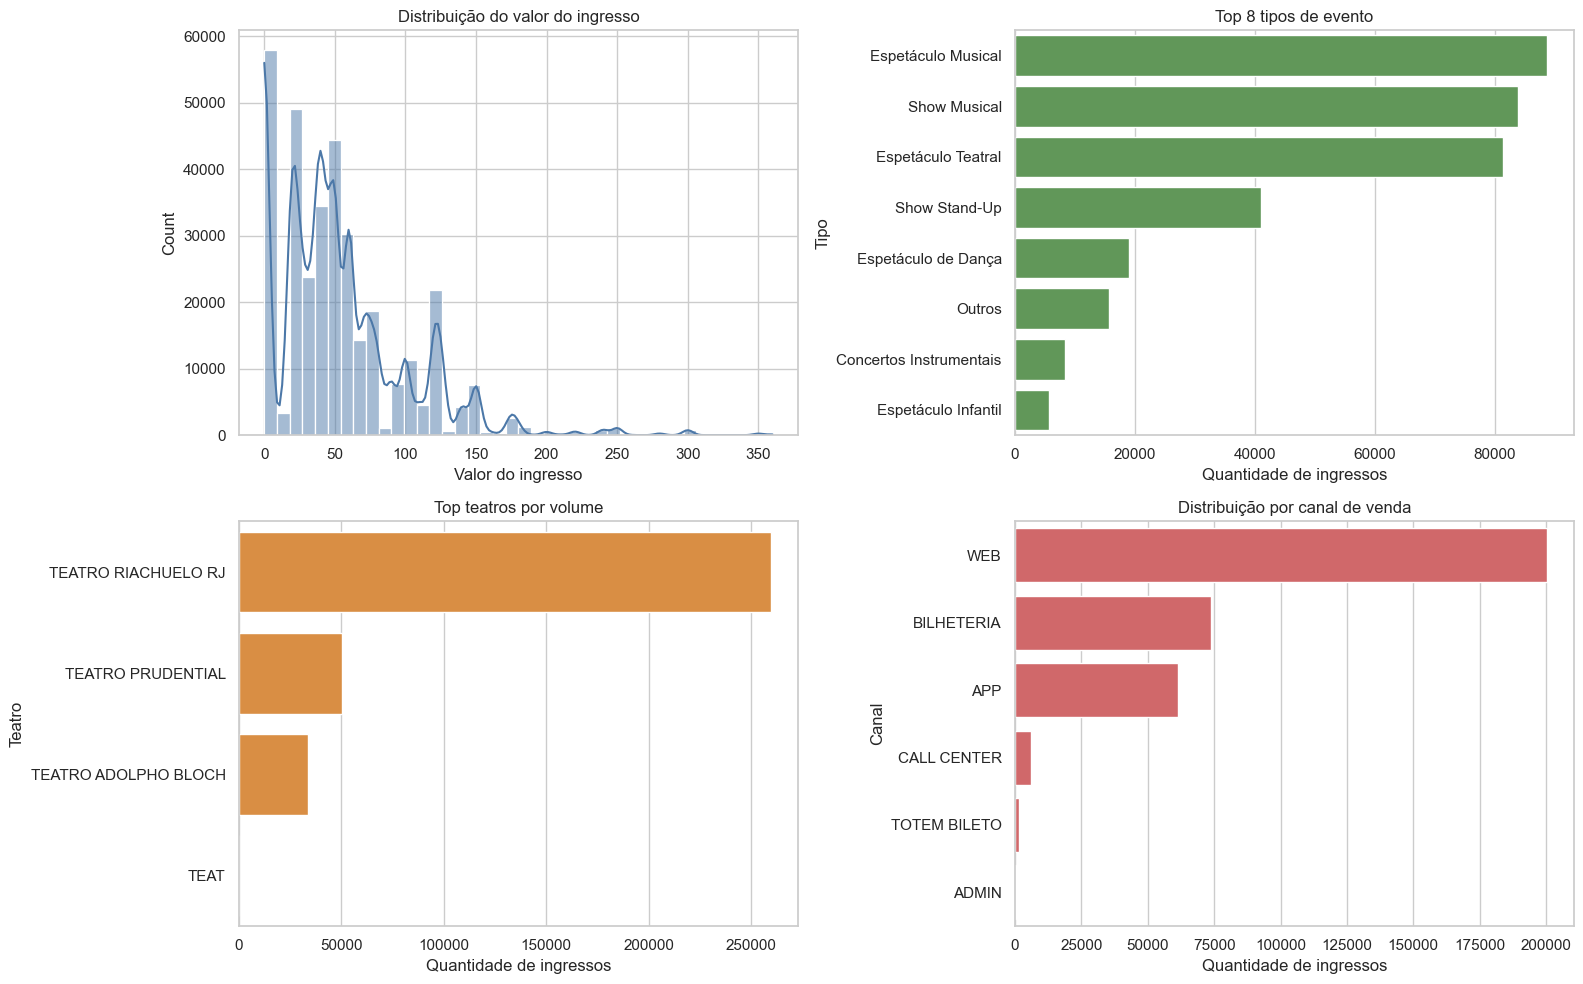

In [10]:
fig, axes = plt.subplots(2, 2, figsize=(16, 10))

# Distribuição de valores
sns.histplot(df_eda["VALOR_NUM"].dropna(), bins=40, kde=True, ax=axes[0, 0], color="#4C78A8")
axes[0, 0].set_title("Distribuição do valor do ingresso")
axes[0, 0].set_xlabel("Valor do ingresso")

# Top tipos
top_tipos = df_eda["TIPO"].value_counts().head(8)
sns.barplot(x=top_tipos.values, y=top_tipos.index, ax=axes[0, 1], color="#59A14F")
axes[0, 1].set_title("Top 8 tipos de evento")
axes[0, 1].set_xlabel("Quantidade de ingressos")
axes[0, 1].set_ylabel("Tipo")

# Top teatros
top_teatros = df_eda["TEATRO"].value_counts().head(8)
sns.barplot(x=top_teatros.values, y=top_teatros.index, ax=axes[1, 0], color="#F28E2B")
axes[1, 0].set_title("Top teatros por volume")
axes[1, 0].set_xlabel("Quantidade de ingressos")
axes[1, 0].set_ylabel("Teatro")

# Canal de venda
canal_counts = df_eda["CANAL DA VENDA"].value_counts()
sns.barplot(x=canal_counts.values, y=canal_counts.index, ax=axes[1, 1], color="#E15759")
axes[1, 1].set_title("Distribuição por canal de venda")
axes[1, 1].set_xlabel("Quantidade de ingressos")
axes[1, 1].set_ylabel("Canal")

plt.tight_layout()
plt.show()

## 3) Análise bivariada

#### Comportamento de compra e diferença de preço entre categorias.

/var/folders/nv/cxjnj7v93ss6407r7sspcqyr0000gp/T/ipykernel_55996/2926988402.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


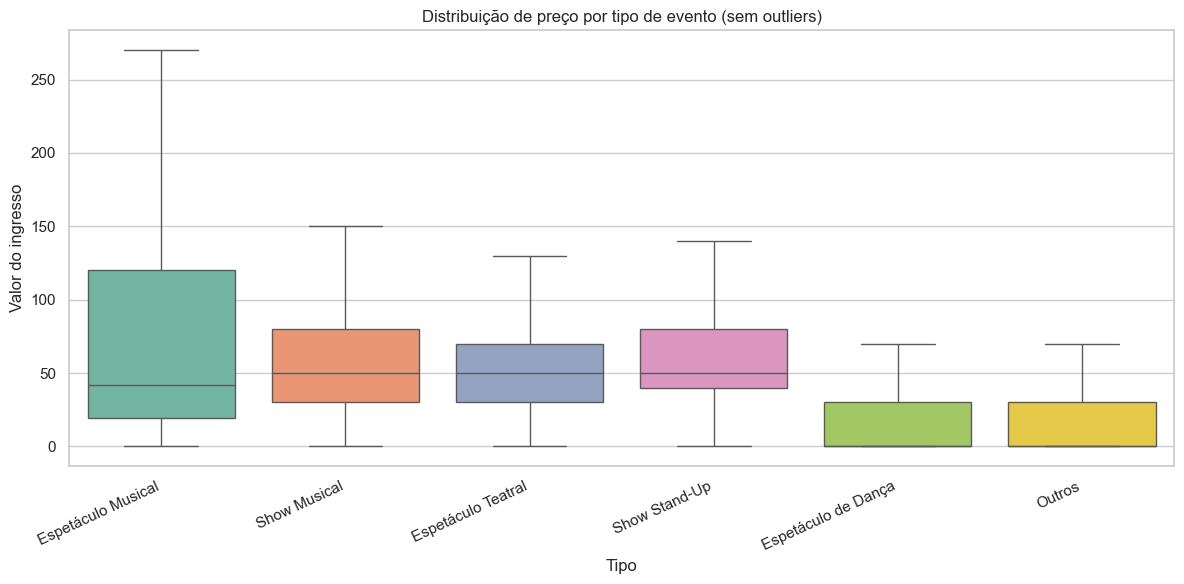

,count,median,mean
TIPO,,,
Espetáculo Teatral,81324,50.0,49.523019
Show Musical,83919,50.0,57.975769
Show Stand-Up,40923,50.0,57.408700
Espetáculo Musical,88738,42.0,69.769237
Espetáculo de Dança,19066,0.0,15.823101
Outros,15677,0.0,15.216596


In [11]:
# Preço por tipo (foco nos tipos com maior volume)
tipos_top = df_eda["TIPO"].value_counts().head(6).index
base_tipos = df_eda[df_eda["TIPO"].isin(tipos_top)].copy()

plt.figure(figsize=(12, 6))
sns.boxplot(
    data=base_tipos,
    x="TIPO",
    y="VALOR_NUM",
    order=tipos_top,
    showfliers=False,
    palette="Set2",
)
plt.xticks(rotation=25, ha="right")
plt.title("Distribuição de preço por tipo de evento (sem outliers)")
plt.xlabel("Tipo")
plt.ylabel("Valor do ingresso")
plt.tight_layout()
plt.show()

base_tipos.groupby("TIPO")["VALOR_NUM"].agg(["count", "median", "mean"]).sort_values("median", ascending=False)

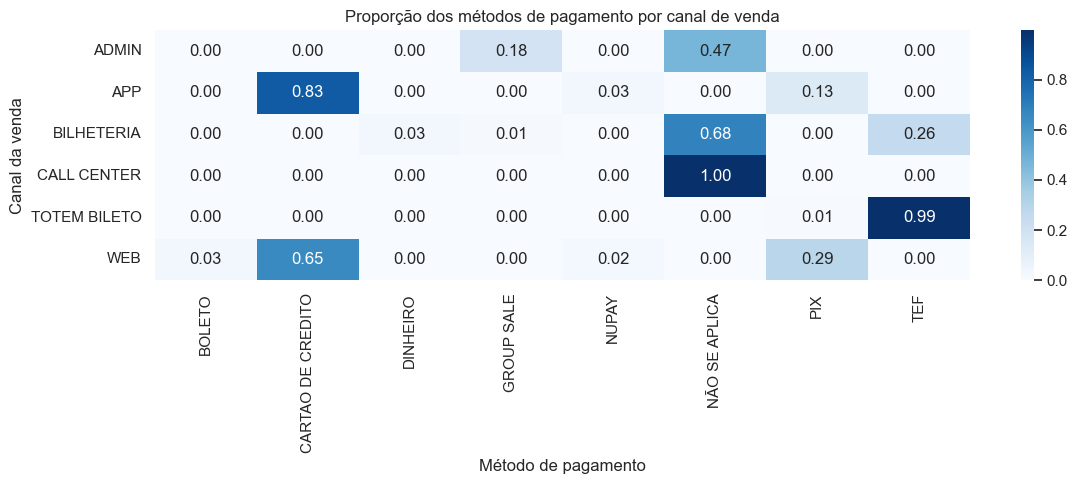

In [12]:
# Relação entre canal de venda e método de pagamento (proporção por canal)
ct = pd.crosstab(df_eda["CANAL DA VENDA"], df_eda["MÉTODO DE PAGAMENTO"], normalize="index")

# Seleciona os métodos mais frequentes para visualização legível
metodos_top = df_eda["MÉTODO DE PAGAMENTO"].value_counts().head(8).index
ct_plot = ct[ct.columns.intersection(metodos_top)]

plt.figure(figsize=(12, 5))
sns.heatmap(ct_plot, annot=True, fmt=".2f", cmap="Blues")
plt.title("Proporção dos métodos de pagamento por canal de venda")
plt.xlabel("Método de pagamento")
plt.ylabel("Canal da venda")
plt.tight_layout()
plt.show()

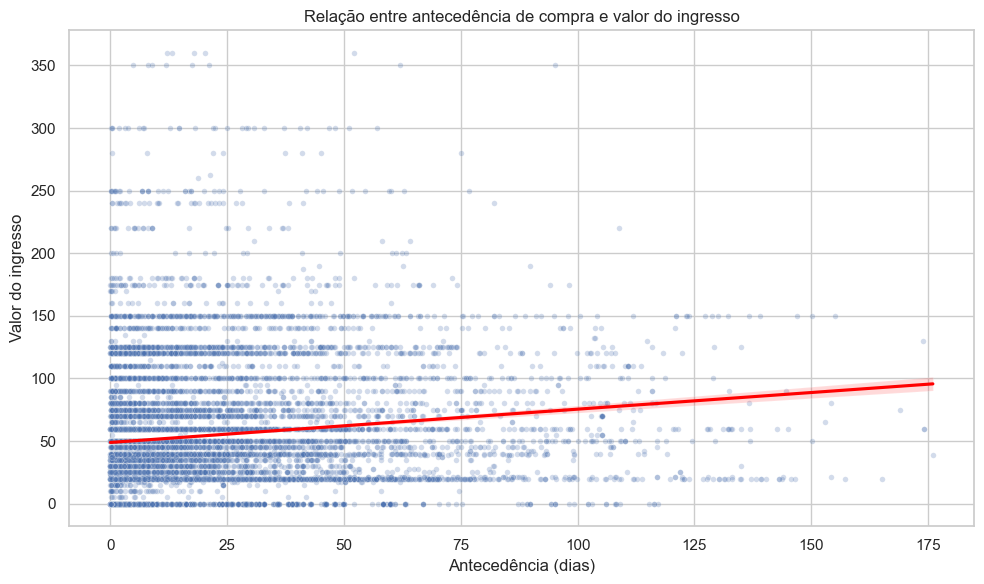

,ANTECEDENCIA_DIAS,VALOR_NUM
ANTECEDENCIA_DIAS,1.000000,0.138736
VALOR_NUM,0.138736,1.000000


In [13]:
# Antecedência de compra vs valor do ingresso (amostra para performance visual)
base_relacao = df_eda[["ANTECEDENCIA_DIAS", "VALOR_NUM"]].dropna().copy()
base_relacao = base_relacao[(base_relacao["ANTECEDENCIA_DIAS"] >= 0) & (base_relacao["ANTECEDENCIA_DIAS"] <= 180)]

amostra = base_relacao.sample(min(12000, len(base_relacao)), random_state=42)

plt.figure(figsize=(10, 6))
sns.scatterplot(data=amostra, x="ANTECEDENCIA_DIAS", y="VALOR_NUM", alpha=0.25, s=16)
sns.regplot(data=amostra, x="ANTECEDENCIA_DIAS", y="VALOR_NUM", scatter=False, color="red")
plt.title("Relação entre antecedência de compra e valor do ingresso")
plt.xlabel("Antecedência (dias)")
plt.ylabel("Valor do ingresso")
plt.tight_layout()
plt.show()

amostra[["ANTECEDENCIA_DIAS", "VALOR_NUM"]].corr()